# Translation, sentiment, and poetic license

This notebook executes the translation exercise through a current public API,
then analyzes the original text of *Pride and Prejudice*, including
every sentence with TextBlob polarity exactly +1 or -1, then compares
TextBlob with author-published Microsoft sentiment scores for Dickinson.

**Dataset substitution:** the assignment's Kaggle notebook names a
597-poem CSV that could not be downloaded. The supplied
[361-poem sample](../data/dickinson-azure.json) comes from the same author's
[eMiLy project](https://github.com/jlooper/eMiLy). Its README identifies the
precomputed sentiment values as Microsoft Cognitive Services output. It is
a different sample; no 597-poem result or new Azure execution is claimed.

In [1]:
import re
from pathlib import Path
import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
from IPython.display import display
from textblob import TextBlob

nltk.data.path.insert(0, str(Path('../data/nltk_data').resolve()))
plt.rcParams.update({'figure.figsize': (8, 4), 'figure.dpi': 110})
examples = [
    'It is a truth universally acknowledged, that a single man in possession of a good fortune, must be in want of a wife.',
    'Darcy, as well as Elizabeth, really loved them; and they were both ever sensible of the warmest gratitude towards the persons who, by bringing her into Derbyshire, had been the means of uniting them.',
    'Great, that was a wonderful waste of time.',
    'Our distress, my dear Lizzy, is very great.',
    'I have the greatest dislike in the world to that sort of thing.',
]
display(pd.DataFrame([
    {'text': text, 'polarity': TextBlob(text).sentiment.polarity,
     'subjectivity': TextBlob(text).sentiment.subjectivity} for text in examples
]))

,text,polarity,subjectivity
0,"It is a truth universally acknowledged, that a...",0.209524,0.271429
1,"Darcy, as well as Elizabeth, really loved them...",0.700000,0.800000
2,"Great, that was a wonderful waste of time.",0.533333,0.583333
3,"Our distress, my dear Lizzy, is very great.",1.000000,0.975000
4,I have the greatest dislike in the world to th...,1.000000,1.000000


## Translation exercise: live service comparison

`TextBlob.translate()` was removed in 0.18.0 ([changelog](https://textblob.readthedocs.io/en/stable/changelog.html)).
Use the documented [MyMemory GET API](https://mymemory.translated.net/doc/spec.php)
with `langpair=en|fr` and `mt=1` to complete the English-to-French exercise.
This is a replacement service, not the original TextBlob/Google backend.

MyMemory combines translation-memory matches with machine translation. The
`created-by` and `model` fields distinguish these: `Public_Corpora` or `MateCat`
are memory provenance, while `MT!` with `model=neural` identifies a neural result.
An exact memory match does not demonstrate a model generalizing to unseen text.
The novel robot sentence supplies an explicit machine-translation example.

The cell makes four live requests, checks successful nonempty results, and saves
complete responses and UTC retrieval times in
[translation-responses.json](translation-responses.json). Re-running needs
internet access and consumes the service's anonymous quota; the [published
limits](https://mymemory.translated.net/doc/usagelimits.php) are 500 bytes per
segment and 5,000 characters per day. Service or quota errors stop the cell
before replacing the saved comparison. The saved responses preserve this run;
future live wording may differ.


In [2]:
import json
from datetime import datetime, timezone
from html import unescape
from urllib.parse import urlencode
from urllib.request import urlopen

translation_examples = [
    "It is a truth universally acknowledged, that a single man in possession of a good fortune, must be in want of a wife!",
    "I have no money.",
    "It's raining cats and dogs.",
    "The orange robot misplaced seven umbrellas beside the silent library.",
]
endpoint = 'https://api.mymemory.translated.net/get'
translation_records = []
for text in translation_examples:
    assert 0 < len(text.encode('utf-8')) <= 500
    query = urlencode({'q': text, 'langpair': 'en|fr', 'mt': 1})
    with urlopen(f'{endpoint}?{query}', timeout=30) as response:
        payload = json.load(response)
    if payload.get('responseStatus') != 200:
        raise RuntimeError(f"Translation service failed: {payload.get('responseDetails', payload)}")
    translated = payload['responseData']['translatedText']
    assert isinstance(translated, str) and translated.strip() and translated != text
    translation_records.append({
        'source': text, 'retrieved_at': datetime.now(timezone.utc).isoformat(),
        'response': payload,
    })

assert any(match.get('created-by') == 'MT!' and match.get('model') == 'neural'
           for match in translation_records[-1]['response']['matches'])
Path('translation-responses.json').write_text(json.dumps({
    'endpoint': endpoint, 'langpair': 'en|fr', 'mt': 1, 'records': translation_records,
}, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')
translation_table = pd.DataFrame([{
    'English': record['source'],
    'French': unescape(record['response']['responseData']['translatedText']),
    'Matching result provenance': ', '.join(sorted({
        match['created-by'] for match in record['response']['matches']
        if unescape(match['translation']) == unescape(record['response']['responseData']['translatedText'])
    })),
} for record in translation_records])
with pd.option_context('display.max_colwidth', None):
    display(translation_table)


,English,French,Matching result provenance
0,"It is a truth universally acknowledged, that a single man in possession of a good fortune, must be in want of a wife!",C’est une vérité presque incontestable qu’un jeune homme possesseur d’une grande fortune doit avoir besoin d’une épouse.,"MateCat, Public_Corpora"
1,I have no money.,Je n'ai pas d'argent.,Public_Corpora
2,It's raining cats and dogs.,Il pleut comme vache qui pisse.,"MateCat, Public_Corpora"
3,The orange robot misplaced seven umbrellas beside the silent library.,Le robot orange égara sept parapluies à côté de la bibliothèque silencieuse.,MT!


## Translation comparison

The saved opening-sentence result uses *presque incontestable* where Austen
writes *universally acknowledged*, and *jeune homme* instead of explicitly
stating that the man is single. Those changes affect meaning even though the
French reads fluently. The money example chooses *argent* appropriately; the
rain example chooses an idiom with a coarse register. Human review still
matters for fidelity and audience.

The novel robot sentence has an explicitly neural result that retains the
orange robot, seven umbrellas, and silent library. The other three selected
results are translation-memory matches, so they are not evidence of a neural
model handling unseen language. These four probes are qualitative checks,
not a benchmark or a general ranking of human and machine translation.

The lesson's quoted human French passage also translates the next English
sentence. Align the same passage before treating the extra clauses as added
meaning or comparing quality. See the [written answers](answers.md) for the
case-by-case analysis and [raw responses](translation-responses.json) for
provenance.


## Novel challenge: remove publishing material before scoring

The downloaded Gutenberg edition includes a publisher introduction,
illustrations, a colophon, and licensing material. Select the novel from its
first sentence through its last sentence, remove illustration captions and
chapter headings, and retain the original wording and negation. The source
file and its licence remain intact beside this notebook.

In [3]:
raw = Path('../data/pride-and-prejudice.txt').read_text(encoding='utf-8-sig')
start_marker = '*** START OF THE PROJECT GUTENBERG EBOOK PRIDE AND PREJUDICE ***'
end_marker = '*** END OF THE PROJECT GUTENBERG EBOOK PRIDE AND PREJUDICE ***'
body = raw.split(start_marker, 1)[1].split(end_marker, 1)[0]
start = body.index('It is a truth universally acknowledged')
finish = body.rindex('had been the means of uniting them.') + len('had been the means of uniting them.')
novel = body[start:finish]
novel = re.sub(r'\[Illustration[^\]]*\]', '', novel, flags=re.DOTALL)
novel = re.sub(r'(?m)^\s*Chapter [IVXLCDM]+\.?\s*$', '', novel)
novel = novel.replace('_', '')
sentences = list(TextBlob(novel).sentences)
scored = pd.DataFrame([
    {'sentence': str(sentence), 'polarity': sentence.sentiment.polarity,
     'subjectivity': sentence.sentiment.subjectivity} for sentence in sentences
])
positive = scored.loc[scored.polarity.eq(1), 'sentence']
negative = scored.loc[scored.polarity.eq(-1), 'sentence']
assert novel.startswith('It is a truth universally acknowledged')
assert novel.endswith('had been the means of uniting them.')
assert 'PROJECT GUTENBERG' not in novel and '[Illustration' not in novel
assert len(scored) > 4000
print('Sentences:', len(scored))
print('Absolutely positive:', len(positive), 'Absolutely negative:', len(negative))
print('More absolutely positive sentences:', len(positive) > len(negative))
for label, collection in [('ABSOLUTELY POSITIVE', positive), ('ABSOLUTELY NEGATIVE', negative)]:
    print('\n' + label)
    for sentence in collection:
        print(sentence.replace('\n', ' '))
scored.loc[scored.polarity.abs().eq(1)].to_csv('extreme-sentences.csv', index=False)

Sentences: 4648
Absolutely positive: 26 Absolutely negative: 14
More absolutely positive sentences: True

ABSOLUTELY POSITIVE
“What an excellent father you have, girls,” said she, when the door was shut.
He walked here, and he walked there, fancying himself so very great!
Mr. Darcy replied, with great intrepidity,--  “Miss Elizabeth Bennet.”  “Miss Elizabeth Bennet!” repeated Miss Bingley.
“Your examination of Mr. Darcy is over, I presume,” said Miss Bingley; “and pray what is the result?”  “I am perfectly convinced by it that Mr. Darcy has no defect.
Family pride, and filial pride, for he is very proud of what his father was, have done this.
That would be the greatest misfortune of all!
How wonderfully these sort of things occur!
She owed her greatest relief to her friend Miss Lucas, who often joined them, and good-naturedly engaged Mr. Collins’s conversation to herself.
The improvement of spending a night in London was added in time, and the plan became as perfect as plan could be.
S

## Poetic license assignment: compare the two scores on identical poems

TextBlob polarity ranges from -1 to +1. The older Microsoft scores in this
dataset range from 0 to 1. Transforming Microsoft scores to `2*s - 1` aligns
their ranges for a scatterplot; it does not calibrate the models. The
three-way labels below use an explicitly chosen neutral band: 0.4–0.6
for Microsoft and -0.2–0.2 for TextBlob. Agreement is between models,
not accuracy against literary interpretation or human ground truth.

In [4]:
poems = pd.read_json('../data/dickinson-azure.json').rename(
    columns={'text': 'poem', 'sentiment': 'azure_score'}
)
assert len(poems) == 361 and poems.poem.notna().all()
assert poems.azure_score.between(0, 1).all()
poems['textblob_polarity'] = poems.poem.map(lambda text: TextBlob(text).sentiment.polarity)
poems['azure_signed'] = 2 * poems.azure_score - 1
poems['azure_label'] = np.select(
    [poems.azure_score.lt(0.4), poems.azure_score.gt(0.6)],
    ['negative', 'positive'], default='neutral',
)
poems['textblob_label'] = np.select(
    [poems.textblob_polarity.lt(-0.2), poems.textblob_polarity.gt(0.2)],
    ['negative', 'positive'], default='neutral',
)
poems['gap'] = (poems.azure_signed - poems.textblob_polarity).abs()
print('Poems:', len(poems))
print('Three-way model agreement:', round(poems.azure_label.eq(poems.textblob_label).mean(), 4))
print('Score Pearson correlation:', round(poems.azure_signed.corr(poems.textblob_polarity), 4))
display(pd.crosstab(poems.azure_label, poems.textblob_label).reindex(
    index=['negative', 'neutral', 'positive'], columns=['negative', 'neutral', 'positive'], fill_value=0
))
sensitivity = []
for band in [0, 0.1, 0.2, 0.3]:
    a = np.select([poems.azure_signed.lt(-band), poems.azure_signed.gt(band)], [-1, 1], default=0)
    b = np.select([poems.textblob_polarity.lt(-band), poems.textblob_polarity.gt(band)], [-1, 1], default=0)
    sensitivity.append({'neutral_band': band, 'agreement': (a == b).mean()})
display(pd.DataFrame(sensitivity))
poems.to_csv('poetry-comparison.csv', index=False)

Poems: 361
Three-way model agreement: 0.1136
Score Pearson correlation: 0.116


textblob_label,negative,neutral,positive
azure_label,,,
negative,12,215,87
neutral,0,16,1
positive,0,17,13


,neutral_band,agreement
0,0.0,0.268698
1,0.1,0.191136
2,0.2,0.113573
3,0.3,0.074792


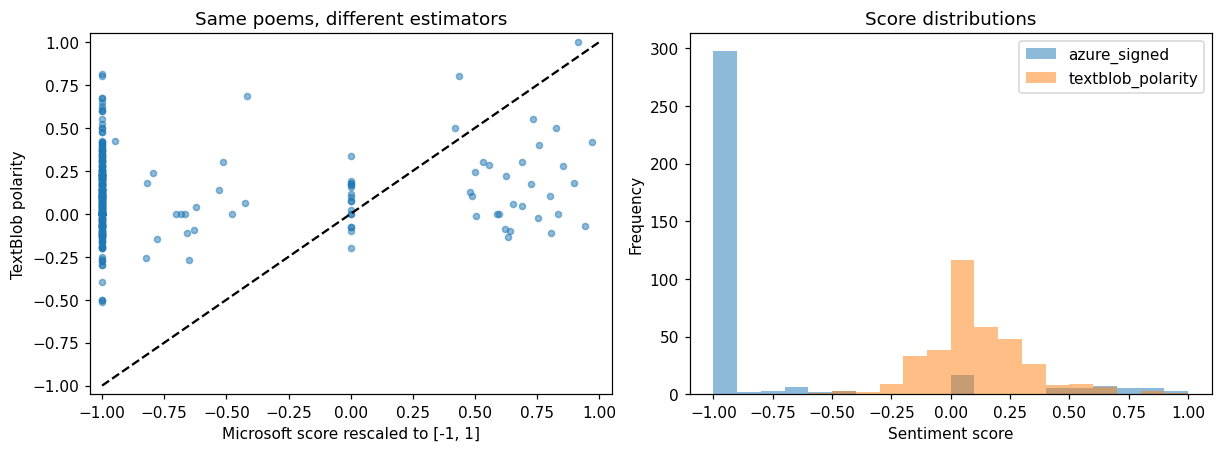


POEM: Dying! Dying in the night!, Won't somebody bring the light, So I can see which way to go, Into the everlasting snow?, And Jesus! Where is Jesus gone?, They said that Jesus -- always came --, Perhaps he doesn't know the House --, This way, Jesus, Let him pass!, Somebody run to the great gate, And see if Dollie's coming! Wait!, I hear her feet upon the stair!, Death won't hurt -- now Dollie's here!
Microsoft: 0.0 negative | TextBlob: 0.8125 positive

POEM: The Butterfly in honored Dust, Assuredly will lie, But none will pass the Catacomb, So chastened as the Fly --
Microsoft: 0.0 negative | TextBlob: 0.8 positive

POEM: When Memory is full, Put on the perfect Lid --, This Morning's finest syllable, Presumptuous Evening said -- 
Microsoft: 0.0 negative | TextBlob: 0.675 positive


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
axes[0].scatter(poems.azure_signed, poems.textblob_polarity, alpha=0.5, s=16)
axes[0].plot([-1, 1], [-1, 1], color='black', linestyle='--')
axes[0].set(xlabel='Microsoft score rescaled to [-1, 1]', ylabel='TextBlob polarity',
            title='Same poems, different estimators', xlim=(-1.05, 1.05), ylim=(-1.05, 1.05))
poems[['azure_signed', 'textblob_polarity']].plot.hist(
    bins=20, alpha=0.5, ax=axes[1], title='Score distributions',
)
axes[1].set_xlabel('Sentiment score')
fig.savefig('poetry-comparison.png', dpi=160)
plt.show()
disagreements = poems.loc[poems.azure_label.ne(poems.textblob_label)].nlargest(3, 'gap')
for _, row in disagreements.iterrows():
    print('\nPOEM:', row.poem)
    print('Microsoft:', round(row.azure_score, 4), row.azure_label,
          '| TextBlob:', round(row.textblob_polarity, 4), row.textblob_label)

## Interpretation and translation compatibility

Disagreement is expected when a poem juxtaposes death, joy, irony, or a
hypothetical speaker. An average of lexicon judgements may differ from the
Microsoft model's sequence-level score. This is a plausible explanation,
not proof of the undocumented version's internal decisions. The printed
poems allow a reader to inspect the largest disagreements. Threshold
sensitivity shows why agreement must be reported with its decision rule.

The opening Austen sentence expresses a social assumption with irony;
positive words do not establish that its speaker is happy. Similarly,
*very great distress* uses an intensifier, and *greatest dislike* is negative
in meaning even if an estimator rewards *greatest*. A wish for someone to
be happy does not imply present happiness. The lesson's negative examples
contain direct distress or disgust, but their exact scores can change
with package versions and sentence boundaries.

**Translation compatibility:** TextBlob removed `translate()` in 0.18.0;
see its [changelog](https://textblob.readthedocs.io/en/stable/changelog.html).
The executed exercise above explicitly replaces that backend with MyMemory
and saves the live responses and their provenance. The original TextBlob
call remains unavailable. Translation needs syntax, idiom, and context;
more training examples alone do not establish superiority to a human
translation, particularly when a quotation includes additional clauses.